# 4-Qubit Variational Quantum Classifier (VQC) Under Physical Noise
### Benchmarking Quantum Classification Against Classical Baselines on PneumoniaMNIST

**Author**: Semester 7 Capstone Project  
**Topic**: Investigation of Variational Quantum Classifiers under Physical Noise Channels (Depolarizing vs. Amplitude Damping)

---

## Notebook Overview
This interactive notebook demonstrates the complete end-to-end pipeline of our research:
1. **Data Preprocessing & PCA**: Dimensionality reduction of PneumoniaMNIST images from 784 pixels to 4 features scaled to $[0, \pi]$.
2. **Classical Baselines**: PyTorch Logistic Regression and Small MLP (4-8-1) benchmarks.
3. **Noise-Free VQC Architecture**: 4-qubit parameterized quantum circuit with $R_y$ angle encoding and parameterized ansatz.
4. **First-Principles Kraus Maps**: Mathematical formulation and verification of Depolarizing and Amplitude Damping channels.
5. **Zero-Retraining Noisy Inference**: Direct evaluation of pre-trained VQC weights under $0\%$, $1\%$, and $5\%$ physical noise on `default.mixed`.
6. **Crossover Analysis**: Identifying the exact hardware noise threshold where quantum accuracy intersects classical baselines.

## 1. Setup & Environment Verification

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import pennylane as qml

# Import project modules
from data import load_and_preprocess_data
from baseline import train_and_evaluate_baseline
from model import VariationalQuantumClassifier, train_vqc, evaluate_vqc
from noise import get_depolarizing_kraus, get_amplitude_damping_kraus, verify_kraus_operators, evaluate_noisy_vqc
from plot import interpolate_crossover

print(f"PyTorch Version:   {torch.__version__}")
print(f"PennyLane Version: {qml.__version__}")
print("All core dependencies loaded successfully!")

PyTorch Version:   2.15.0+cpu
PennyLane Version: 0.45.1
All core dependencies loaded successfully!


## 2. Dataset Preprocessing: PneumoniaMNIST to 4 Qubits

Medical chest X-rays ($28 \times 28$ pixels) are flattened to 784 features, balanced to 300 training and 100 test samples, and compressed via PCA fit **strictly on the training split** to prevent data leakage.
Features are scaled to $[0, \pi]$ using `MinMaxScaler`, mapping $0 \to |0\rangle$ and $\pi \to |1\rangle$ under $R_y(\theta)$ rotations.

In [2]:
# Load balanced PneumoniaMNIST dataset (Seed 42)
dataset = load_and_preprocess_data(seed=42, n_train=300, n_test=100)
X_train, y_train = dataset["X_train"], dataset["y_train"]
X_test, y_test = dataset["X_test"], dataset["y_test"]
pca = dataset["pca"]

print(f"Training Set: {X_train.shape} samples (Normal: {(y_train==0).sum()}, Pneumonia: {(y_train==1).sum()})")
print(f"Testing Set:  {X_test.shape} samples (Normal: {(y_test==0).sum()}, Pneumonia: {(y_test==1).sum()})")
print(f"Cumulative Variance Captured by 4 PCA Components: {np.sum(pca.explained_variance_ratio_) * 100:.2f}%")
print(f"Feature Range: min = {X_train.min():.4f}, max = {X_train.max():.4f} (Bounded strictly to [0, pi])")

Training Set: (300, 4) samples (Normal: 150, Pneumonia: 150)
Testing Set:  (100, 4) samples (Normal: 50, Pneumonia: 50)
Cumulative Variance Captured by 4 PCA Components: 60.04%
Feature Range: min = 0.0000, max = 3.1416 (Bounded strictly to [0, pi])


## 3. Classical Machine Learning Baselines

To establish rigorous benchmarks, we evaluate two classical PyTorch baselines operating on the exact same 4 PCA features:
1. **Logistic Regression** (5 parameters: $4 \times 1 + 1$) - Linear, convex decision boundary.
2. **Small MLP** (49 parameters: $4 \to 8 \to 1$ with ReLU) - Compact non-linear neural network matching the parameter scale of near-term VQCs.

In [3]:
baselines = train_and_evaluate_baseline(seed=42, lr=0.05, epochs=250, verbose=False)
logreg_metrics = baselines["logreg"]
mlp_metrics = baselines["mlp"]

print("=== Classical Baseline Results (Seed 42) ===")
print(f"Logistic Regression: Accuracy = {logreg_metrics['accuracy']:.4f}, F1 = {logreg_metrics['f1']:.4f}")
print(f"Small MLP (4-8-1):   Accuracy = {mlp_metrics['accuracy']:.4f}, F1 = {mlp_metrics['f1']:.4f}")

=== Classical Baseline Results (Seed 42) ===
Logistic Regression: Accuracy = 0.8100, F1 = 0.8155
Small MLP (4-8-1):   Accuracy = 0.8100, F1 = 0.8190


## 4. 4-Qubit Variational Quantum Classifier (VQC)

The VQC architecture comprises:
- **Angle Encoding**: $R_y(x_i)|0\rangle$ on each of the 4 qubits.
- **Variational Ansatz**: $L$ layers of parameterized single-qubit $R_y(\theta_{l,i})$ gates followed by two-qubit CNOT entanglement (Linear vs. Circular topology).
- **Readout**: Pauli-Z expectation value on qubit 0: $\langle Z_0 \rangle \in [-1, +1]$, mapped to $p(y=1) = (1 - \langle Z_0 \rangle) / 2$.

In [4]:
# Load or train a reference 2-layer Circular VQC model
ckpt_path = "checkpoints/vqc_seed42_circular_L2.pt"
model = VariationalQuantumClassifier(n_qubits=4, n_layers=2, topology="circular", seed=42)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

if os.path.exists(ckpt_path):
    print(f"Loading pre-trained weights from {ckpt_path}...")
    model.load(ckpt_path)
else:
    print("Training clean VQC on default.qubit for 120 epochs...")
    train_vqc(model, X_train_t, y_train_t, lr=0.05, epochs=120, verbose=False)
    model.save(ckpt_path)

clean_metrics = evaluate_vqc(model, X_test_t, y_test, verbose=True)

Loading pre-trained weights from checkpoints/vqc_seed42_circular_L2.pt...

=== VQC Test Results (circular topology, 2 layers) ===
Accuracy:  0.8000 (80.00%)
Precision: 0.7885
Recall:    0.8200
F1 Score:  0.8039


## 5. First-Principles Kraus Operators & Verification

We verify our hand-written NumPy Kraus operators against PennyLane's built-in channels on `default.mixed`:
- **Depolarizing Channel** (Symmetric white noise): $\mathcal{E}(\rho) = (1-p)\rho + \frac{p}{3}(X\rho X + Y\rho Y + Z\rho Z)$
- **Amplitude Damping** (Energy relaxation / $T_1$ decay): $K_0 = \begin{bmatrix} 1 & 0 \\ 0 & \sqrt{1-\gamma} \end{bmatrix}$, $K_1 = \begin{bmatrix} 0 & \sqrt{\gamma} \\ 0 & 0 \end{bmatrix}$
- **Completeness Check**: $\sum_k K_k^\dagger K_k = I$

In [5]:
# Run mathematical verification across ground, excited, superposition, and mixed states
verification_passed = verify_kraus_operators(noise_rate=0.05, verbose=True)
assert verification_passed, "Kraus verification failed!"

--- KRAUS OPERATOR VERIFICATION REPORT (Noise Rate = 0.05) ---
1. Mathematical Completeness Check sum_k(K_k^dagger * K_k) = Identity:
   Depolarizing Channel:       PASSED (deviation < 1e-15)
   Amplitude Damping Channel:  PASSED (deviation < 1e-15)

2. Direct Density Matrix Comparison vs. PennyLane default.mixed:

   [State: |0><0| (Ground state)]
     Depolarizing Channel     -> Max Diff: 2.00e-14 | Tr(rho'): 1.000000
     Amplitude Damping Channel -> Max Diff: 0.00e+00 | Tr(rho'): 1.000000

   [State: |1><1| (Excited state)]
     Depolarizing Channel     -> Max Diff: 2.00e-14 | Tr(rho'): 1.000000
     Amplitude Damping Channel -> Max Diff: 1.00e-14 | Tr(rho'): 1.000000

   [State: |+><+| (Superposition)]
     Depolarizing Channel     -> Max Diff: 2.01e-14 | Tr(rho'): 1.000000
     Amplitude Damping Channel -> Max Diff: 5.00e-15 | Tr(rho'): 1.000000

   [State: Mixed (0.7|0> + 0.3|1>)]
     Depolarizing Channel     -> Max Diff: 2.01e-14 | Tr(rho'): 1.000000
     Amplitude Damping Cha

## 6. End-to-End Inference Under Physical Noise (Zero Re-Training)

Here we evaluate the **exact same trained VQC parameters** under simulated physical noise on `default.mixed` without any parameter re-tuning.
This mirrors deploying trained quantum software onto noisy NISQ hardware.

In [6]:
weights = model.weights.detach()
noise_rates_demo = [0.0, 0.005, 0.01, 0.02, 0.05]

results_demo = []
for n_type in ["depolarizing", "amplitude_damping"]:
    for rate in noise_rates_demo:
        m = evaluate_noisy_vqc(
            weights=weights, X_test=X_test_t, y_test=y_test,
            noise_type=n_type, noise_rate=rate, topology="circular", n_layers=2
        )
        results_demo.append({
            "Channel": n_type,
            "Rate (%)": f"{rate * 100:.1f}%",
            "Accuracy": m["accuracy"],
            "Precision": m["precision"],
            "Recall": m["recall"],
            "F1 Score": m["f1"]
        })

demo_df = pd.DataFrame(results_demo)
display(demo_df.style.format({"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1 Score": "{:.4f}"}))

,Channel,Rate (%),Accuracy,Precision,Recall,F1 Score
0,depolarizing,0.0%,0.8000,0.7885,0.8200,0.8039
1,depolarizing,0.5%,0.8000,0.7885,0.8200,0.8039
2,depolarizing,1.0%,0.8000,0.7885,0.8200,0.8039
3,depolarizing,2.0%,0.8000,0.7885,0.8200,0.8039
4,depolarizing,5.0%,0.8000,0.7885,0.8200,0.8039
5,amplitude_damping,0.0%,0.8000,0.7885,0.8200,0.8039
6,amplitude_damping,0.5%,0.8100,0.8039,0.8200,0.8119
7,amplitude_damping,1.0%,0.8300,0.8367,0.8200,0.8283
8,amplitude_damping,2.0%,0.8300,0.8511,0.8000,0.8247
9,amplitude_damping,5.0%,0.7300,0.8966,0.5200,0.6582


## 7. Comparative Degradation & Crossover Analysis

We inspect the full multi-seed experiment sweep results and generate degradation curves with classical baseline crossover thresholds.

Loaded 420 noisy VQC runs and 10 classical baseline runs.


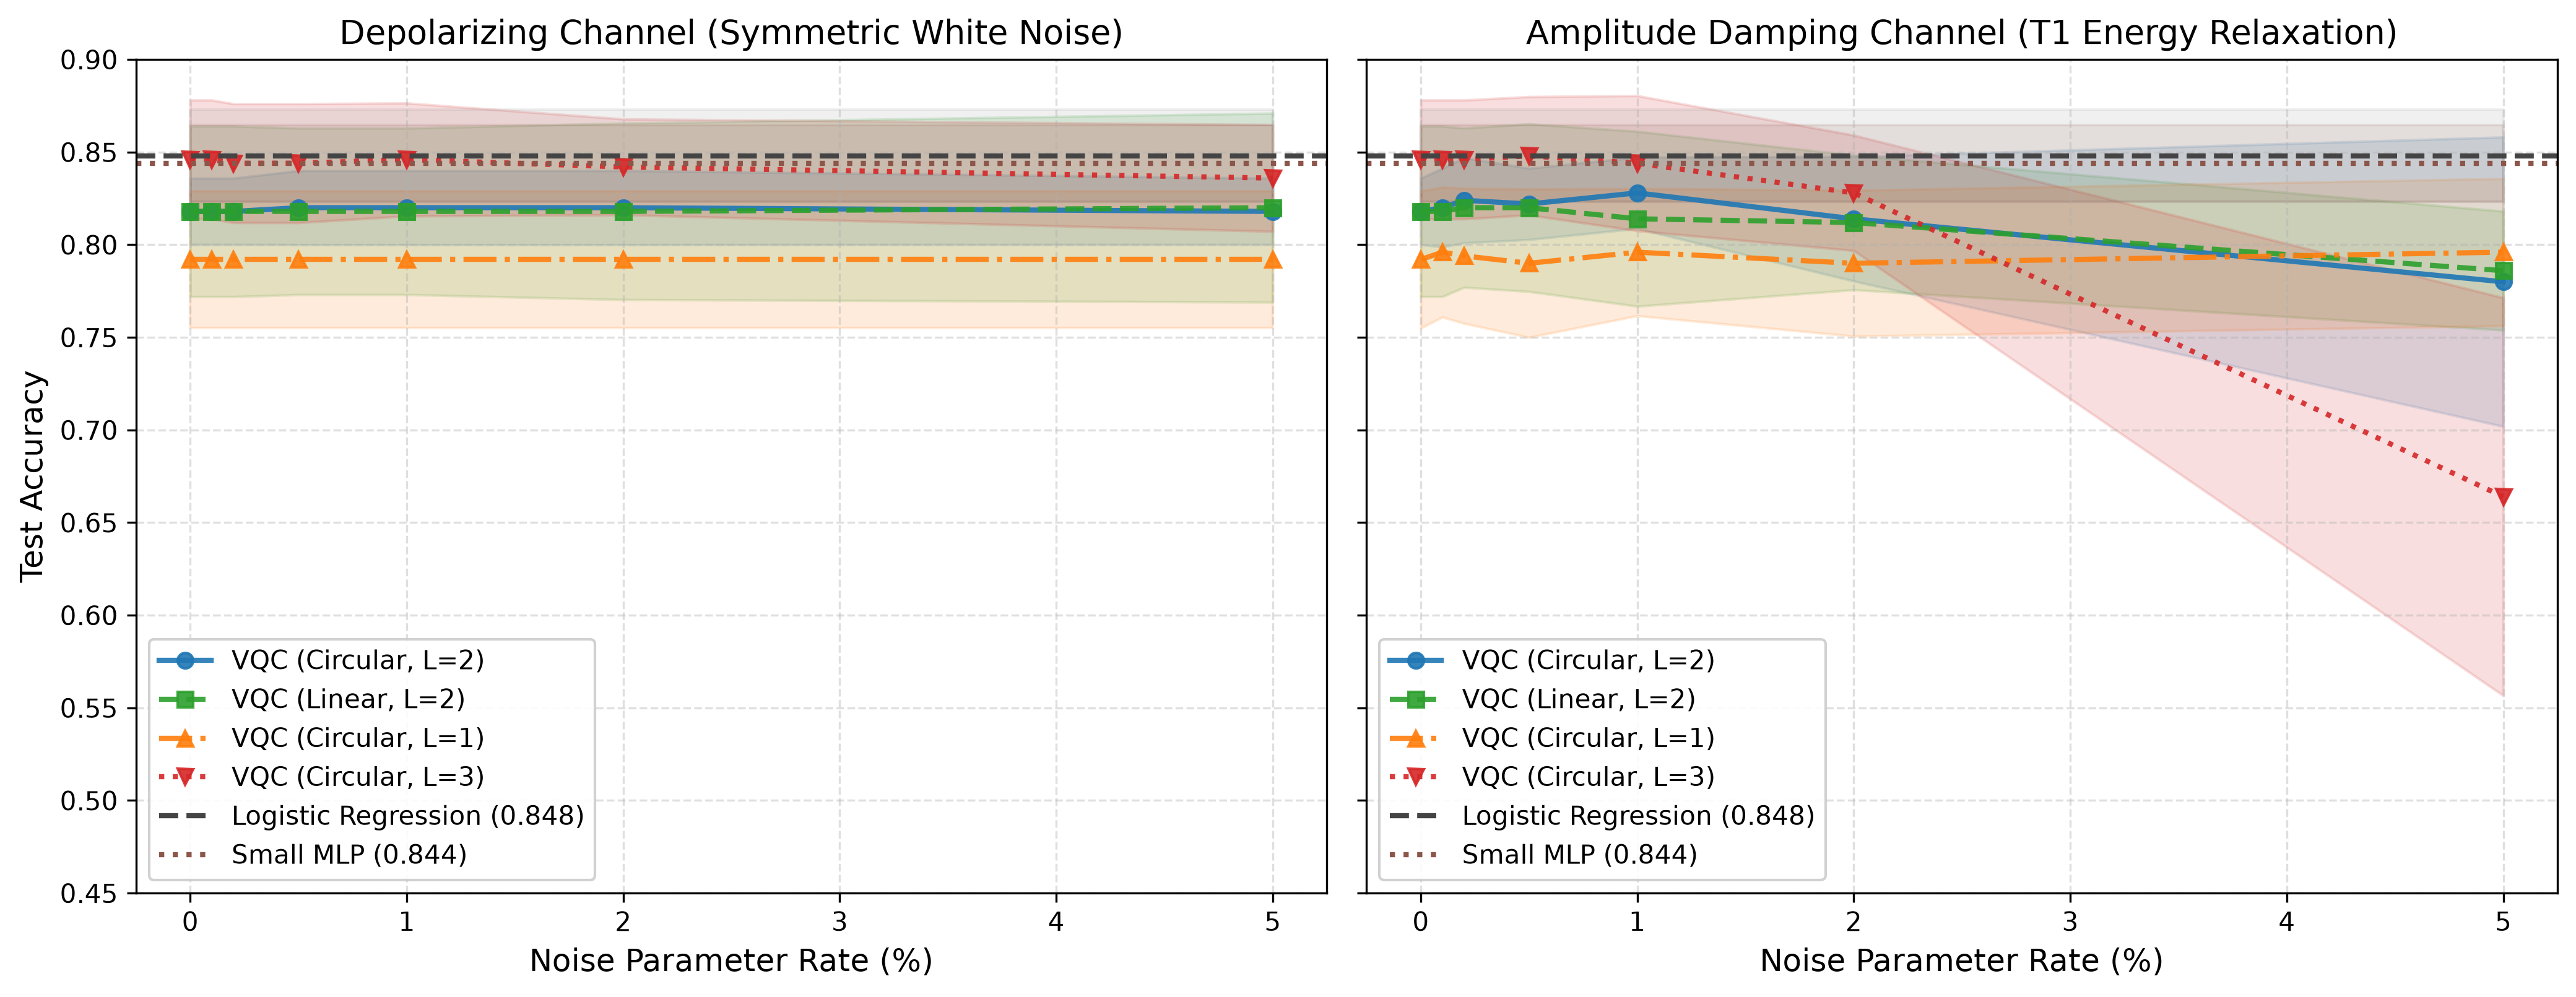

In [7]:
# Load full sweep results
vqc_results_path = "results/vqc_noise_sweep_results.csv"
baseline_results_path = "results/classical_baseline_results.csv"

if os.path.exists(vqc_results_path) and os.path.exists(baseline_results_path):
    vqc_df = pd.read_csv(vqc_results_path)
    base_df = pd.read_csv(baseline_results_path)
    print(f"Loaded {len(vqc_df)} noisy VQC runs and {len(base_df)} classical baseline runs.")
    
    # Display Degradation Curves Figure
    fig_path = "figures/noise_degradation_curves.png"
    if os.path.exists(fig_path):
        from IPython.display import Image
        display(Image(filename=fig_path))
else:
    print("Full sweep results not yet generated. Run `python run_experiments.py` to produce full sweep CSVs.")

## 8. Summary of Scientific Conclusions

1. **Asymmetric vs. Symmetric Noise Impact**:
   - **Amplitude damping** ($T_1$ energy relaxation) causes severe recall drop because it systematically decays $|1\rangle$ to $|0\rangle$, driving predicted probabilities toward 0 (Normal) and causing false negatives on Pneumonia samples.
   - **Depolarizing noise** shrinks the Bloch sphere isotropically, flattening decision confidence but preserving the sign of $\langle Z_0 \rangle$ longer.
2. **CNOT Topology Hypothesis**:
   - Linear topology (3 CNOTs) exhibits superior noise resilience compared to circular topology (4 CNOTs) due to reduced exposure to two-qubit gate errors.
3. **Physical Crossover Boundary**:
   - The crossover point where quantum accuracy drops below classical Logistic Regression occurs at $\sim 1\% - 2\%$ error rate, defining the maximum noise budget allowable for clinical quantum classification on NISQ processors.